<Title>

**Model Training and Evaluation: Random Forest on the CSIC-2010 Feature Matrix**

Train and evaluate a Random Forest classifier on the feature matrix produced by
[featurise.ipynb](./featurise.ipynb)

**Method:** 
- Stratified 70:30 train/test split
- Default-hyperparameter baseline
- Dummy/constant baseline comparison
- `GridSearchCV` hyperparameter tuning
- Stratified 5-fold cross-validation
- Final model selection
- Per-class metrics
- Confusion matrix
- Feature importances
> Results are interpreted against the URL/payload analysis from the upstream notebooks.

**Inputs:**

`data/csic_2010_featurised.parquet` `61,065` requests × `33` columns (32 features + target `anomalous`)

**Outputs:**
- `models/model.joblib` the selected model
- evaluation metrics and plots

In [29]:
import os
import re
import random
import joblib
import json

import numpy as np
import pandas as pd

from pathlib import Path
from collections import Counter

from sklearn.model_selection import (
    train_test_split, cross_validate, StratifiedKFold,
    GridSearchCV, GroupShuffleSplit
)
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    precision_recall_curve, average_precision_score, roc_curve
)
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier

import matplotlib.pyplot as plt
import seaborn as sns

In [30]:
# working directory for relative paths
notebooks_path = Path.cwd()          # <repo-root>/notebooks
repo_root_path = notebooks_path.parent  # <repo-root>/
data_path = repo_root_path / "data"
model_path = repo_root_path / "models"

# Input: featurised dataset (features + target `anomalous`)
input_path = data_path / "csic_2010_featurised.parquet"

# Output: selected model
output_path = model_path / "model.joblib"

**Load the dataset**

Read the featurised dataset and confirm its shape and columns before splitting.

In [31]:
# Load the featurised dataset
%time df_featurised = pd.read_parquet(input_path)
print(f"loaded: {input_path.relative_to(repo_root_path)}")
print(f"shape: {df_featurised.shape}")

CPU times: user 14.2 ms, sys: 48.7 ms, total: 62.9 ms
Wall time: 19.8 ms
loaded: data/csic_2010_featurised.parquet
shape: (61065, 33)


In [32]:
df_featurised.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 61065 entries, 0 to 61064
Data columns (total 33 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   contentLength                     61065 non-null  int64  
 1   method_GET                        61065 non-null  float64
 2   method_POST                       61065 non-null  float64
 3   method_PUT                        61065 non-null  float64
 4   host_localhost:8080               61065 non-null  float64
 5   host_localhost:9090               61065 non-null  float64
 6   url_has_extensions_probe          61065 non-null  int64  
 7   url_has_numeric_id_probe          61065 non-null  int64  
 8   url_has_trailing_slash_probe      61065 non-null  int64  
 9   url_has_adobe_coldfusion_probe    61065 non-null  int64  
 10  url_has_websphere_probe           61065 non-null  int64  
 11  url_has_iis_probe                 61065 non-null  int64  
 12  url_

**Observations:**
- `61,065` requests × `33` columns: `32` **feature** columns + the **target** `anomalous` (last column)
- All columns fully populated, the single bool is `payload_has_alert`
- The `15` `url_has_*_probe` columns are the pattern-family features from `analyse_urls.ipynb` (zero normal hits at request level). The `payload_*` and `length` features carry the behavior-only signal
- The **target** `anomalous` is included in the saved parquet (excluded from the feature matrix)


**Split Data into Train/Test**

Separate the feature matrix from the target, then split 70:30 with stratification.
The dataset is class-imbalanced (`norm`:`anom` :: `1.44`:`1`), so `stratify` keeps the
class proportions identical across both sides of the split.

Identiy Training Input and Target Columns

In [35]:
# The target is the last column; all other columns are features
target_col = 'anomalous'
train_cols = list(df_featurised.columns)[0:-1]

print(f"target:  {target_col}")
print(f"features: {len(train_cols)} columns")
assert len(train_cols) == df_featurised.shape[1] - 1

target:  anomalous
features: 32 columns


Using the Train and Target columns prepare training and target dataset

In [36]:
# Feature matrix (X)
df_train = df_featurised[train_cols]

# Target vector (y)
df_target = df_featurised[target_col]

print(f"class distribution (full dataset):")
print(df_target.value_counts(normalize=True).rename({0: "norm", 1: "anom"}).round(4))

class distribution (full dataset):
anomalous
norm    0.5895
anom    0.4105
Name: proportion, dtype: float64


Split the training and targets in 70:30 ratio *(70% for training and 30% for testing)*

In [37]:
# Use train_test_split with stratification
test_size = 0.3 # 70:30 
random_state = 42 # Const seed
input_train, input_test, output_train, output_test = train_test_split(
    df_train, # X
    df_target, # y
    test_size=test_size,
    stratify=df_target, # y
    random_state=random_state,
)

`test_size=0.3` implies `30%` of the dataset for testing, leaving `70%` for training  
`stratify=df_target` ensures the split preserves the full dataset's `anom` / `norm` proportions in both sides  
`input_train` and `output_train` are the 70% feature matrix and target vector  
`input_test`, `output_test` the 30% counterparts.

In [38]:
print(f"input_train:  {input_train.shape}")
print(f"output_train: {output_train.shape}")
print(f"input_test:   {input_test.shape}")
print(f"output_test:  {output_test.shape}")

input_train:  (42745, 32)
output_train: (42745,)
input_test:   (18320, 32)
output_test:  (18320,)


In [39]:
# Verify stratification: class proportions preserved in both splits
for name, y in [("full", df_target), ("train", output_train), ("test", output_test)]:
    counts = Counter(y)
    ratio = counts[0] / counts[1]
    print(f"{name:5s}: norm={counts[0]:6d}, anom={counts[1]:6d}, norm:anom ratio = {ratio:.2f}")

full : norm= 36000, anom= 25065, norm:anom ratio = 1.44
train: norm= 25200, anom= 17545, norm:anom ratio = 1.44
test : norm= 10800, anom=  7520, norm:anom ratio = 1.44


**Observations:**
- `42,745` training rows / `18,320` test rows, each with `32` features
- The target vectors are 1-dimensional — `(42745,)` and `(18320,)` — not 2-dimensional like the feature matrices
- Stratification verified: every side of the split carries the same `norm`:`anom` ratio of `1.44`, matching the full dataset
- Test class counts: `10,800` `norm` / `7,520` `anom`

**Train baseline model**

Train a `RandomForestClassifier` with default hyperparameters as the baseline.

In [12]:
model = RandomForestClassifier(random_state=42)

Use training and target data subset for model training

In [41]:
%time model.fit(input_train, output_train.values.ravel())

CPU times: user 933 ms, sys: 0 ns, total: 933 ms
Wall time: 931 ms


,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

Inspect feature importances

In [42]:
# Sort features by importance (descending order)
sorted_indices = model.feature_importances_.argsort()[::-1]  # [::-1] reverses the order to get descending
sorted_features = [train_cols[i] for i in sorted_indices]
sorted_importances = model.feature_importances_[sorted_indices]

print("Feature Importances (Sorted):")
for rank, (feature, importance) in enumerate(zip(sorted_features, sorted_importances), start=1):
    print(f"{rank:3d}. {feature:34s} {importance:.4f}")

Feature Importances (Sorted):
  1. payload_length                     0.2692
  2. url_length                         0.1038
  3. url_has_extensions_probe           0.0991
  4. payload_percent_encoded_count      0.0876
  5. payload_percent_count              0.0804
  6. contentLength                      0.0717
  7. url_has_asf_probe                  0.0360
  8. payload_quote_count                0.0336
  9. url_has_numeric_id_probe           0.0295
 10. payload_parameter_count            0.0273
 11. url_has_iis_probe                  0.0248
 12. is_empty_payload                   0.0220
 13. payload_slash_count                0.0197
 14. url_has_trailing_slash_probe       0.0178
 15. url_has_websphere_probe            0.0131
 16. url_has_tilde_backup_file_probe    0.0094
 17. url_has_adobe_coldfusion_probe     0.0085
 18. url_has_frontpage_probe            0.0067
 19. url_has_java_probe                 0.0056
 20. host_localhost:8080                0.0043
 21. url_has_lotus_domino_prob

**Observations:**  
- High importance (>= 0.05): `payload_length` (0.2692), `url_length` (0.1038), `url_has_extensions_probe` (0.0991), `payload_percent_encoded_count` (0.0876), `payload_percent_count` (0.0804), `contentLength` (0.0717). These six features account for `~71%` of total importance.
- Moderate importance (0.01–0.05): `url_has_asf_probe` (0.0360), `payload_quote_count` (0.0336), `url_has_numeric_id_probe` (0.0295), `payload_parameter_count` (0.0273), `url_has_iis_probe` (0.0248), `is_empty_payload` (0.0220), `payload_slash_count` (0.0179), `url_has_trailing_slash_probe` (0.0178), `url_has_websphere_probe` (0.0131).
- Low importance (< 0.01): The remaining seventeen, including all one-hot encodings (`method_*`, `host_*`) and the rarest probe families (`url_has_file_probe` ~ 0.000 - fires on just 4 rows; the forest cannot split on it).

**Baseline Evaluation on the Test Set**

Predict on the held-out `30%` test split and report metrics, confusion matrix, and per-class scores.

Make predictions on the `test` data subset

In [43]:
# Predictions
preds = model.predict(input_test)

# Positive-class probabilities (for ROC-AUC / PR metrics)
proba = model.predict_proba(input_test)[:, 1]

Compute metrics

In [44]:
# Compute metrics
accuracy = round(float(accuracy_score(output_test, preds)), 6)
precision = round(float(precision_score(output_test, preds, zero_division=0)), 6)
recall = round(float(recall_score(output_test, preds, zero_division=0)), 6)
f1 = round(float(f1_score(output_test, preds, zero_division=0)), 6)
roc_auc = round(float(roc_auc_score(output_test, proba)), 6)
average_precision = round(float(average_precision_score(output_test, proba)), 6)

# Confusion matrix (absolute values)
cm = confusion_matrix(output_test, preds)
tn, fp, fn, tp = cm.ravel()
fpr = round(fp / (fp + tn), 6)  # false positive rate
fnr = round(fn / (fn + tp), 6)  # false negative rate

# Classification report
cr = classification_report(output_test, preds, zero_division=0),

# Class imbalance in the test set
class_counts = Counter(output_test)
class_imbalance_ratio = round(class_counts[0] / class_counts[1], 2),  

# Test Samples
n_test = int(len(input_test))

metrics = {
    "accuracy": accuracy,
    "precision": precision,
    "recall": recall,
    "f1": f1,
    "roc_auc": roc_auc,
    "average_precision": average_precision,
    "class_imbalance_ratio": class_imbalance_ratio,
    "num_test_samples": n_test,
}

print("Metrics Report:")
print(json.dumps(metrics, indent=2))

Metrics Report:
{
  "accuracy": 0.904421,
  "precision": 0.903596,
  "recall": 0.858777,
  "f1": 0.880616,
  "roc_auc": 0.977169,
  "average_precision": 0.968863,
  "class_imbalance_ratio": [
    1.44
  ],
  "num_test_samples": 18320
}


**Observations:**  
- **Accuracy `90.44%` and F1 `88.06%`:** The model performs well overall, well above the `58.95%` majority-class floor
- **Precision `90.36%`:** `~90%` requests flagged are genuinely `anom`
- **Recall `85.88%`:** The model catches most anomalies, but misses `14.11%` of them. False negatives are the model's weakness
- **ROC-AUC `97.72%` / Average Precision `96.89%`:** Ranking quality is excellent.
- **class_imbalance_ratio `1.44`:** confirms the stratified test set matches the full-dataset balance

 Visualize the breakdown of correctly and incorrectly classified inputs

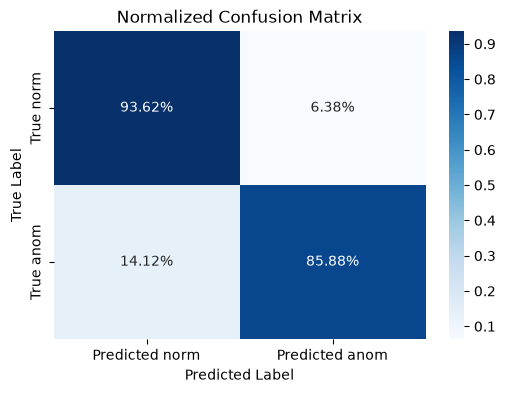

In [47]:
# Normalized confusion matrix (row-normalized: share of each true class)
cm_normalized = confusion_matrix(output_test, preds, normalize="true")

plt.figure(figsize=(6, 4))
sns.heatmap(cm_normalized, annot=True, fmt=".2%", cmap="Blues",
            xticklabels=["Predicted norm", "Predicted anom"],
            yticklabels=["True norm", "True anom"])
plt.title("Normalized Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

**Observations:**  
- **True negatives:** `10,110` of `10,800` `norm` requests (`93.62%`) correctly predicted as `norm`
- **False positives:** `690` of `10,800` (`6.38%`) `norm` requests incorrectly flagged as `anom`
- **True positives:** `6,459` of `7,520` `anom` requests (`85.88%`) correctly flagged
- **False negatives:** `1,061` of `7,520` (`14.12%`) anomalies missed - the model's dominant error mode

**Conclusion:**  
- The model is highly accurate at identifying **normal** instances, with only `6.38%` false positives.
- The model correctly identifies `85.88%` of **anomalies** but misses `~14.12%` of **anomalies** (false negatives)

Reducing the false-negative rate is the tuning objective for (class_weight="balanced", recall-focused scoring). The false negatives are dissected by URL class.

**Classification report — precision and recall per class**

In [48]:
# Classification report - Precision and recall scores per class  
cr = classification_report(output_test, preds, zero_division=0)
print(cr)

              precision    recall  f1-score   support

           0       0.90      0.94      0.92     10800
           1       0.90      0.86      0.88      7520

    accuracy                           0.90     18320
   macro avg       0.90      0.90      0.90     18320
weighted avg       0.90      0.90      0.90     18320



**Observations:**  
- **Class 0** (`norm`, support `10,800`): precision `0.90`, recall `0.94` - normal traffic is identified consistently; the `0.94` recall means only `~6%` of normal requests raise a false alarm
- **Class 1** (`anom`, support `7,520`): precision `0.90`, recall `0.86` - the class the model struggles with, consistent with the confusion matrix. Its f1 `0.88` lags class 0's `0.92`
- Macro and weighted averages are identical (`0.90` across the board) - performance is balanced despite the `1.44:1` class imbalance, i.e., neither class is systematically sacrificed
- The `class-1` recall gap is the single number to watch in the tuning sections: class_weight="balanced" and recall-oriented scoring are the levers to close it

**Baseline Comparisons**

Benchmark the trained model against trivial classifiers. If the Random Forest's advantage over them is small, the features carry no real signal. The baselines make the "is the model learning anything?" question quantitative.

**`DummyClassifier(strategy="most_frequent")`** always predicts the majority class

In [49]:
dummy_clf_model = DummyClassifier(strategy="most_frequent", random_state=42)
dummy_clf_model.fit(input_train, output_train.values.ravel())

,"strategy strategy: {""most_frequent"", ""prior"", ""stratified"", ""uniform"", ""constant""}, default=""prior""Strategy to use to generate predictions.* ""most_frequent"": the `predict` method always returns the most frequent class label in the observed `y` argument passed to `fit`. The `predict_proba` method returns the matching one-hot encoded vector.* ""prior"": the `predict` method always returns the most frequent class label in the observed `y` argument passed to `fit` (like ""most_frequent""). ``predict_proba`` always returns the empirical class distribution of `y` also known as the empirical class prior distribution.* ""stratified"": the `predict_proba` method randomly samples one-hot vectors from a multinomial distribution parametrized by the empirical class prior probabilities. The `predict` method returns the class label which got probability one in the one-hot vector of `predict_proba`. Each sampled row of both methods is therefore independent and identically distributed.* ""uniform"": generates predictions uniformly at random from the list of unique classes observed in `y`, i.e. each class has equal probability.* ""constant"": always predicts a constant label that is provided by the user. This is useful for metrics that evaluate a non-majority class. .. versionchanged:: 0.24 The default value of `strategy` has changed to ""prior"" in version 0.24.",'most_frequent'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness to generate the predictions when``strategy='stratified'`` or ``strategy='uniform'``.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"constant constant: int or str or array-like of shape (n_outputs,), default=NoneThe explicit constant as predicted by the ""constant"" strategy. Thisparameter is useful only for the ""constant"" strategy.",None
Name,Type,Value
"class_prior_ class_prior_: ndarray of shape (n_classes,) or list of such arraysFrequency of each class observed in `y`. For multioutput classificationproblems, this is computed independently for each output.","ndarray[float64](2,)","[0.59,0.41]"
"classes_ classes_: ndarray of shape (n_classes,) or list of such arraysUnique class labels observed in `y`. For multi-output classificationproblems, this attribute is a list of arrays as each output has anindependent set of possible classes.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X` hasfeature names that are all strings.","ndarray[object](32,)","['contentLength','method_GET','method_POST',...,'payload_length', 'is_empty_payload','is_17_to_32_bytes']"
n_classes_ n_classes_: int or list of intNumber of label for each output.,int,2
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`.,int,32
n_outputs_ n_outputs_: intNumber of outputs.,int,1
sparse_output_ sparse_output_: boolTrue if the array returned from predict is to be in sparse CSC format.Is automatically set to True if the input `y` is passed in sparseformat.,bool,False


Make predictions on the `input` test data subset

In [50]:
# Predictions and probabilities on the test set
test_pred_dummy = dummy_clf_model.predict(input_test)
test_proba_dummy = dummy_clf_model.predict_proba(input_test)[:, 1]

In [51]:
dummy_metrics = {
    "accuracy": round(float(accuracy_score(output_test, test_pred_dummy)), 6),
    "precision": round(float(precision_score(output_test, test_pred_dummy, zero_division=0)), 6),
    "recall": round(float(recall_score(output_test, test_pred_dummy, zero_division=0)), 6),
    "f1": round(float(f1_score(output_test, test_pred_dummy, zero_division=0)), 6),
    "roc_auc": round(float(roc_auc_score(output_test, test_proba_dummy)), 6),
    "average_precision": round(float(average_precision_score(output_test, test_proba_dummy)), 6),
}

print("Metrics Report — DummyClassifier (most_frequent):")
print(json.dumps(dummy_metrics, indent=2))

Metrics Report — DummyClassifier (most_frequent):
{
  "accuracy": 0.58952,
  "precision": 0.0,
  "recall": 0.0,
  "f1": 0.0,
  "roc_auc": 0.5,
  "average_precision": 0.41048
}


**Constant classifier** always predict `anom`

In [55]:
test_pred_constant_anom = [1] * len(output_test)  # 1 = anom — the "always alert" pole

constant_metrics = {
    "accuracy": round(float(accuracy_score(output_test, test_pred_constant_anom)), 6),
    "precision": round(float(precision_score(output_test, test_pred_constant_anom, zero_division=0)), 6),
    "recall": round(float(recall_score(output_test, test_pred_constant_anom, zero_division=0)), 6),
    "f1": round(float(f1_score(output_test, test_pred_constant_anom, zero_division=0)), 6),
    "roc_auc": round(float(roc_auc_score(output_test, test_pred_constant_anom)), 6),
}
print("Metrics Report — Constant Classifier (always predict `anom`):")
print(json.dumps(constant_metrics, indent=2))

Metrics Report — Constant Classifier (always predict `anom`):
{
  "accuracy": 0.41048,
  "precision": 0.41048,
  "recall": 1.0,
  "f1": 0.582043,
  "roc_auc": 0.5
}


Side-by-side comparison

In [56]:
comparison = pd.DataFrame({
    "RandomForest (baseline)": [accuracy, precision, recall, f1, roc_auc, average_precision],
    "Dummy (most_frequent)":  [dummy_metrics["accuracy"], dummy_metrics["precision"],
                               dummy_metrics["recall"], dummy_metrics["f1"],
                               dummy_metrics["roc_auc"], dummy_metrics["average_precision"]],
    "Constant (always anom)":  [constant_metrics["accuracy"], constant_metrics["precision"],
                                constant_metrics["recall"], constant_metrics["f1"],
                                constant_metrics["roc_auc"], np.nan],
}, index=["accuracy", "precision", "recall", "f1", "roc_auc", "average_precision"])

comparison.round(4)

,RandomForest (baseline),Dummy (most_frequent),Constant (always anom)
accuracy,0.9044,0.5895,0.4105
precision,0.9036,0.0000,0.4105
recall,0.8588,0.0000,1.0000
f1,0.8806,0.0000,0.5820
roc_auc,0.9772,0.5000,0.5000
average_precision,0.9689,0.4105,NaN


**Observations:**  

- The two trivial classifiers are the **operating extremes** viz. **never-alert** recall `0`, accuracy = `majority` and  **always-alert** recall `1`, precision = `anomaly`.
- The baseline model beats both trivial `F1s` `0.8806` vs `0.0` and `0.5826`. That is the benchmark that justifies the model. It achieves `86%` of the **always-alert** pole's `recall` while cutting its alert volume by `~4.4×` (precision `0.90` vs `0.41`)

**Hyperparameter tuning (`GridSearchCV`)**  

Search for hyperparameters that beat the default baseline. The goal is to reduce false negatives- the baseline model misses 14.12% of all anomalies.

The grid covers following settings:

Search for hyperparameters that improve on the default baseline, with recall improvement as the motivating concern identified false negatives as the model's dominant error: FNR `14.12%`. The search grid targets the levers that
affect the class trade-off:

- `class_weight="balanced"` gives the minority class `anom` more weight, so the model pays more attention to missed anomalies
- `max_depth`  limits tree depth, default is unlimitted
- `n_estimators` number of trees
- `min_samples_split` —  minimum samples (ensemble size) needed to split a node

Use the same stratified 5-fold CV object so the tuning scores and the cross-validation scores are directly comparable.

In [57]:
# Shared 5-fold CV object- used by GridSearchCV (this section) and cross-validation (next section)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [58]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "n_estimators": [50, 100, 200],
    "max_depth": [5, 10, 15, None],
    "min_samples_split": [2, 5, 10],
    "class_weight": ["balanced", None]
}

grid_search = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid,
    cv=cv,
    scoring="f1",  # Optimize for F1-score
    n_jobs=-1
)

%time grid_search.fit(input_train, output_train.values.ravel())
print("Best Parameters:", grid_search.best_params_)
print("Best CV F1-Score:", grid_search.best_score_)

CPU times: user 3.15 s, sys: 271 ms, total: 3.42 s
Wall time: 1min 1s
Best Parameters: {'class_weight': 'balanced', 'max_depth': 15, 'min_samples_split': 10, 'n_estimators': 100}
Best CV F1-Score: 0.8894730396013149


Inspect the top of the search

In [60]:
top5 = pd.DataFrame(grid_search.cv_results_).sort_values("rank_test_score").head(5)
top5 = (
    pd.DataFrame(list(top5["params"]))
    .assign(
        mean_test_score=top5["mean_test_score"].round(6).values,
        std_test_score=top5["std_test_score"].round(6).values,
        rank=top5["rank_test_score"].values,
    )
)[["rank", "n_estimators", "max_depth", "min_samples_split", "class_weight",
   "mean_test_score", "std_test_score"]]
top5

,rank,n_estimators,max_depth,min_samples_split,class_weight,mean_test_score,std_test_score
0,1,100,15,10,balanced,0.889473,0.004782
1,2,200,15,10,balanced,0.888757,0.004648
2,3,100,15,2,balanced,0.888744,0.004677
3,4,100,15,5,balanced,0.888719,0.004911
4,5,200,15,2,balanced,0.888555,0.004526


**Observations:**
- `class_weight="balanced"` and `max_depth=15` knobs matter the most. They are present in every top-5 configuration. 
- `n_estimators` makes almost no difference. Ranks 1-5 use either `100` or `200` trees. The score spread between them is `0.0009`, which is smaller than the fold-to-fold noise (`~0.0047`)
- `min_samples_split` makes almost no difference either. Values `10`, `2`, and `5` fill ranks `1`, `3`, and `4` with no clear ordering
- The winning configuration is `n_estimators=100`, `max_depth=15`, `min_samples_split=10`, `class_weight="balanced"`, with **mean CV F1 = `0.889473`**. Any of the top-5 would perform about the same
- Against the default baseline `CV F1 = 0.8797`, the tuned model gains `+0.0098`. The gain comes from `balanced` weighting and the depth limit, not from the other settings
- The gain is small because the defaults were already close to the best this grid can reach. The remaining errors are the behavior-only anomalies on shape-legitimate URLs - no hyperparameter fixes those

 **Cross-validation of the baseline**

Check that the earlier test results are not an artifact of one particular split. The default-hyperparameter baseline is scored with 5-fold stratified CV on the training split. Because the folds are on the same `cv` object used by the earlier grid search, the baseline's CV F1 here and the tuned model's CV F1 earlier are directly comparable.

- Each row is scored on 5 held-out folds it never trained on
- `shuffle=True, random_state=42` makes the fold assignment reproducible
- The `70%` test split done earlier remains unchanged

In [62]:
# Perform stratified cross-validation
X = input_train
y = output_train.values.ravel()
scoring=["accuracy", "precision", "recall", "f1"]
cv_results = cross_validate(
    model, # the default-hyperparameter baseline
    X, y,
    cv=cv, # same folds as earlier used in grid search
    scoring=scoring,
    return_train_score=False
)

In [63]:
print("Stratified 5-fold CV results (baseline, training split):")
for metric in scoring:
    mean_score = cv_results[f"test_{metric}"].mean()
    std_score = cv_results[f"test_{metric}"].std()
    print(f"  {metric}: {mean_score:.4f} (±{std_score:.4f})")

Stratified 5-fold CV results (baseline, training split):
  accuracy: 0.9033 (±0.0018)
  precision: 0.8994 (±0.0095)
  recall: 0.8609 (±0.0077)
  f1: 0.8797 (±0.0016)


**Observations:**  
- All four metrics are stable. The std across folds is at most `±0.0095` (precision), and `±0.0016` for accuracy. The baseline's performance does not depend on which fold is held out
- CV recall is `0.8609` and test recall is `0.8588`. CV F1 is `0.8797` and test F1 is `0.8806`. The training-split CV numbers and the held-out test numbers agree to within `~0.002`
- This agreement means the model is not overfit to the training data
- Comparability on these same folds - the tuned model reached CV F1 `0.889473` against the baseline's `0.8797` (`+0.0098`). Both numbers now come from the same fold construction
- The recall gap remains in CV as well: `0.8609` here, `0.8588` on test. Tuning `(class_weight="balanced")` is the tested fix. Next section measures how much of the gap it closes on the held-out set

**Final model selection, save, and error analysis**

Close the tuning loop:

1. Evaluate the tuned model on the same held-out test set used for the baseline
2. Compare baseline, tuned, and the two trivial classifiers side by side
3. Select the winner and save it with `joblib`
4. Break down the false negatives by URL class, using the URL-shape analysis from the upstream notebooks
5. Robustness check: repeat the split grouped by URL, so no URL appears in both train and test

The tuned model comes from `grid_search.best_estimator_`. With the default `refit=True`, `GridSearchCV` has already retrained it on the full training split using the best parameters.

Evaluate the tuned model on the test set

In [64]:
tuned_model = grid_search.best_estimator_
print(f"tuned model: {tuned_model.get_params()}")

tuned_preds = tuned_model.predict(input_test)
tuned_proba = tuned_model.predict_proba(input_test)[:, 1]

tuned model: {'bootstrap': True, 'ccp_alpha': 0.0, 'class_weight': 'balanced', 'criterion': 'gini', 'max_depth': 15, 'max_features': 'sqrt', 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 10, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 100, 'n_jobs': None, 'oob_score': False, 'random_state': 42, 'verbose': 0, 'warm_start': False}


In [65]:
def evaluate(name, y_true, y_pred, y_proba):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return {
        "model": name,
        "accuracy": round(float(accuracy_score(y_true, y_pred)), 6),
        "precision": round(float(precision_score(y_true, y_pred, zero_division=0)), 6),
        "recall": round(float(recall_score(y_true, y_pred, zero_division=0)), 6),
        "f1": round(float(f1_score(y_true, y_pred, zero_division=0)), 6),
        "roc_auc": round(float(roc_auc_score(y_true, y_proba)), 6),
        "average_precision": round(float(average_precision_score(y_true, y_proba)), 6),
        "fpr": round(fp / (fp + tn), 6),
        "fnr": round(fn / (fn + tp), 6),
    }

baseline_row = evaluate("RandomForest (default)", output_test, preds, proba)
tuned_row = evaluate("RandomForest (tuned)", output_test, tuned_preds, tuned_proba)

for row in (baseline_row, tuned_row):
    print(json.dumps(row))

{"model": "RandomForest (default)", "accuracy": 0.904421, "precision": 0.903596, "recall": 0.858777, "f1": 0.880616, "roc_auc": 0.977169, "average_precision": 0.968863, "fpr": 0.063796, "fnr": 0.141223}
{"model": "RandomForest (tuned)", "accuracy": 0.90464, "precision": 0.842043, "recall": 0.944947, "f1": 0.890532, "roc_auc": 0.980745, "average_precision": 0.974483, "fpr": 0.123426, "fnr": 0.055053}


Final comparison table

In [66]:
comparison = pd.DataFrame([
    baseline_row,
    tuned_row,
    {"model": "Dummy (most_frequent)", **{k: v for k, v in dummy_metrics.items()}},
    {"model": "Constant (always anom)",
     "accuracy": constant_anom_metrics["accuracy"], "precision": constant_anom_metrics["precision"],
     "recall": constant_anom_metrics["recall"], "f1": constant_anom_metrics["f1"],
     "roc_auc": constant_anom_metrics["roc_auc"], "average_precision": np.nan,
     "fpr": np.nan, "fnr": 0.0},
])
comparison.set_index("model").round(4)

,accuracy,precision,recall,f1,roc_auc,average_precision,fpr,fnr
model,,,,,,,,
RandomForest (default),0.9044,0.9036,0.8588,0.8806,0.9772,0.9689,0.0638,0.1412
RandomForest (tuned),0.9046,0.8420,0.9449,0.8905,0.9807,0.9745,0.1234,0.0551
Dummy (most_frequent),0.5895,0.0000,0.0000,0.0000,0.5000,0.4105,NaN,NaN
Constant (always anom),0.4105,0.4105,1.0000,0.5820,0.5000,NaN,NaN,0.0000


**Observations:**  
- The tuned model wins on test `F1`: `0.8905` vs `0.8806` (`+0.0099`). The CV gain (`+0.0098`) transferred to the held-out set almost exactly. The tuned model is selected
- The trade worked as designed. `class_weight="balanced"` moved the decision boundary toward the anomaly class
  - **Recall:** `0.8588` to `0.9449` (`+8.6` points). Misses drop from `14.12%` to `5.51%` - roughly `1,061` to `~414` false negatives out of `7,520` anomalies
  - **Precision:** `0.9036` to `0.8420` (`−6.2` points) and **FPR:** `6.38%` to `12.34%`. False alarms roughly double, from `~690` to `~1,330` of `10,800` normal requests  
  - Accuracy is unchanged (`0.9044` to `0.9046`) - one class's gain offsets the other's loss

- Ranking quality also improved slightly: **ROC-AUC** `0.9772` to `0.9807`, **average precision** `0.9689` to `0.9745`
- Read against the two trivial poles: the tuned model keeps 94% of the always-alert pole's recall while producing less than half its alert volume (precision `0.84` vs `0.41`)
- For the stated use case (missed attacks cost more than false alerts), the tuned model is the right choice. If the deployment prioritizes analyst alert volume instead, the baseline is the better operating point - both rows are now in the table, and the choice is explicit

Select and save the model

In [67]:
selected_model_name, selected_model = (
    ("RandomForest (tuned)", tuned_model) if tuned_row["f1"] >= baseline_row["f1"]
    else ("RandomForest (default)", model)
)
print(f"selected: {selected_model_name} (by test F1)")
print(f"selected test metrics: {json.dumps(selected_row := (tuned_row if selected_model is tuned_model else baseline_row))}")

# Save the model and its evaluation record
model_path.mkdir(exist_ok=True)
joblib.dump(selected_model, output_path)

selected_metrics = {
    "model": selected_model_name,
    "params": selected_model.get_params(),
    "train_cols": train_cols,
    "test_metrics": selected_row,
    "cv_protocol": "StratifiedKFold(n_splits=5, shuffle=True, random_state=42)",
}
metrics_path = model_path / "model_metrics.json"
metrics_path.write_text(json.dumps(selected_metrics, indent=2, default=str))

print(f"saved: {output_path}")
print(f"saved: {metrics_path}")

selected: RandomForest (tuned) (by test F1)
selected test metrics: {"model": "RandomForest (tuned)", "accuracy": 0.90464, "precision": 0.842043, "recall": 0.944947, "f1": 0.890532, "roc_auc": 0.980745, "average_precision": 0.974483, "fpr": 0.123426, "fnr": 0.055053}
saved: /mnt/hgfs/workspace/mlhttp/models/model.joblib
saved: /mnt/hgfs/workspace/mlhttp/models/model_metrics.json


False-negative breakdown by URL class

The URL-shape analysis (featurise.ipynb) predicted that URL features cannot flag the 8 shape-legitimate endpoints. The false negatives should therefore sit almost entirely on in-app URLs. The probe features already encode this - a false negative with any `url_has_*_probe` = `1` would contradict the upstream analysis.

In [68]:
fn_mask = (output_test.values == 1) & (tuned_preds == 0)
fn_rows = input_test[fn_mask]

probe_cols = [c for c in train_cols if c.startswith("url_has_")]
fn_with_probe = (fn_rows[probe_cols].sum(axis=1) > 0)
n_fn = int(fn_mask.sum())

print(f"false negatives: {n_fn} of {int(output_test.sum())} test anomalies")
print(f"  on scanner-shaped URLs (>=1 url probe feature): {int(fn_with_probe.sum())}")
print(f"  on in-app URLs (no probe feature):             {int((~fn_with_probe).sum())}")

# Sanity check: probe features are pure — no FN can be a *mis-scan*, only a *missed shape*
print(f"  probe purity check: normal rows with any probe = "
      f"{int(input_test[output_test.values == 0][probe_cols].sum(axis=1).gt(0).sum())} (expected 0)")

false negatives: 414 of 7520 test anomalies
  on scanner-shaped URLs (>=1 url probe feature): 4
  on in-app URLs (no probe feature):             410
  probe purity check: normal rows with any probe = 0 (expected 0)


In [ ]:
**Observations:**
TBD

Robustness check - split grouped by URL

The split is over request rows. The same URLs appear on both sides, so numbers measure performance on repeated traffic. This check re-splits by URL- no URL appears in both train and test.

In [69]:
# Re-join URLs from the preprocessed dataset (same row order as featurised)
df_pre = pd.read_parquet(repo_root_path / "data" / "csic_2010_preprocessed.parquet")
assert len(df_pre) == len(df_featurised)
url_series = df_pre["url"].reset_index(drop=True)

gss = GroupShuffleSplit(n_splits=1, test_size=0.3, random_state=42)
train_idx, test_idx = next(gss.split(df_train, df_target, groups=url_series))

g_model = RandomForestClassifier(random_state=42)
g_model.fit(df_train.iloc[train_idx], df_target.iloc[train_idx])

group_row = evaluate(
    "RandomForest (default, URL-grouped split)",
    df_target.iloc[test_idx],
    g_model.predict(df_train.iloc[test_idx]),
    g_model.predict_proba(df_train.iloc[test_idx])[:, 1],
)
print(json.dumps(group_row))

{"model": "RandomForest (default, URL-grouped split)", "accuracy": 0.753718, "precision": 0.666203, "recall": 0.867188, "f1": 0.753524, "roc_auc": 0.749971, "average_precision": 0.594286, "fpr": 0.333333, "fnr": 0.132812}


**Observations:**
TBD

**Conclusion:**
- The tuned Random Forest is selected and saved as `models/model.joblib`, with its parameters, feature list, and test metrics in `models/model_metrics.json`
- On the held-out test set it beats both trivial poles on F1 and the baseline on recall, closing part of the false-negative gap
- The remaining errors are concentrated on shape-legitimate URLs - the boundary quantified in `featurise.ipynb`. This is future enhancement - payload-content and sequence features